# 基于 MIMIC-IV Demo 的 ICU 延长住院预测
## Early Prediction of Prolonged ICU Stay Using the MIMIC-IV Clinical Database Demo

**研究问题 / Research question**

利用入 ICU 后 24 小时内的 demographics、生命体征、实验室检查与早期干预信息，预测患者是否会发生 **延长 ICU 停留（ICU LOS ≥ 72 小时）**。

**数据来源 / Data source**

MIMIC-IV Clinical Database Demo v2.2（PhysioNet, DOI: 10.13026/dp1f-ex47），包含 100 名患者的去标识化住院与 ICU 记录，可公开获取，无需 credentialed access。

**流程 / Pipeline**

1. 数据读取 Data reading
2. 数据预处理 Preprocessing & cohort construction
3. 统计分析 Statistical analysis
4. 预测模型建立 Predictive modeling
5. 模型评估与可视化 Evaluation & visualization
6. 结果导出（供报告与项目网页使用）Export for report & website

> 说明：Demo 数据库样本量小（128 个首次 ICU 住院、48 个事件），本分析用于展示可复现的临床预测建模流程，结果不应外推为临床结论。

## 0. 环境与全局设置 / Setup

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy import stats
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    roc_curve, precision_recall_curve, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
)
from sklearn.calibration import calibration_curve
import xgboost as xgb
import shap
import joblib

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "mimic-iv-clinical-database-demo-2.2"
FIG_DIR = ROOT / "report" / "figures"
TAB_DIR = ROOT / "report" / "tables"
OUT_DIR = ROOT / "notebooks" / "outputs"
for d in (FIG_DIR, TAB_DIR, OUT_DIR, OUT_DIR / "models"):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PALETTE = {"No": "#4C72B0", "Yes": "#C44E52"}
COLORS = {"Logistic": "#4C72B0", "Random Forest": "#55A868", "XGBoost": "#C44E52"}


def savefig(fig, name):
    """Save a figure as both PNG (web) and PDF (LaTeX)."""
    fig.savefig(FIG_DIR / f"{name}.png")
    fig.savefig(FIG_DIR / f"{name}.pdf")
    return FIG_DIR / f"{name}.png"


print("Project root:", ROOT)
print("Data directory:", DATA)
print("Python:", __import__("sys").version.split()[0])

Project root: /mnt/lustre/home/yangjicheng/projects/icu_los
Data directory: /mnt/lustre/home/yangjicheng/projects/icu_los/data/mimic-iv-clinical-database-demo-2.2
Python: 3.13.13


/mnt/lustre/home/yangjicheng/projects/icu_los/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 数据读取 / Data reading

MIMIC-IV 分为 `hosp`（住院）与 `icu`（重症监护）两个模块；本分析使用其中的患者、住院、ICU stay、生命体征、实验室检查、液体输注与操作事件表。

In [2]:
patients = pd.read_csv(DATA / "hosp" / "patients.csv.gz")
admissions = pd.read_csv(
    DATA / "hosp" / "admissions.csv.gz",
    parse_dates=["admittime", "dischtime", "deathtime", "edregtime", "edouttime"],
)
icustays = pd.read_csv(
    DATA / "icu" / "icustays.csv.gz",
    parse_dates=["intime", "outtime"],
)
d_items = pd.read_csv(DATA / "icu" / "d_items.csv.gz")
d_labitems = pd.read_csv(DATA / "hosp" / "d_labitems.csv.gz")

print("patients        :", patients.shape)
print("admissions      :", admissions.shape)
print("icustays        :", icustays.shape)
display(patients.head(3))
display(admissions[["subject_id", "hadm_id", "admittime", "admission_type", "hospital_expire_flag"]].head(3))
display(icustays.head(3))

patients        : (100, 6)
admissions      : (275, 16)
icustays        : (140, 8)


,subject_id,gender,anchor_age,anchor_year,anchor_year_group,dod
0,10014729,F,21,2125,2011 - 2013,NaN
1,10003400,F,72,2134,2011 - 2013,2137-09-02
2,10002428,F,80,2155,2011 - 2013,NaN


,subject_id,hadm_id,admittime,admission_type,hospital_expire_flag
0,10004235,24181354,2196-02-24 14:38:00,URGENT,0
1,10009628,25926192,2153-09-17 17:08:00,URGENT,0
2,10018081,23983182,2134-08-18 02:02:00,URGENT,0


,subject_id,hadm_id,stay_id,first_careunit,last_careunit,intime,outtime,los
0,10018328,23786647,31269608,Neuro Stepdown,Neuro Stepdown,2154-04-24 23:03:44,2154-05-02 15:55:21,7.703
1,10020187,24104168,37509585,Neuro Surgical Intensive Care Unit (Neuro SICU),Neuro Stepdown,2169-01-15 04:56:00,2169-01-20 15:47:50,5.453
2,10020187,26842957,32554129,Neuro Intermediate,Neuro Intermediate,2170-02-24 18:18:46,2170-02-25 15:15:26,0.873


### 1.1 生命体征与实验室检查

使用 MIMIC-IV 标准 itemid 提取入 ICU 后 24 小时内的生命体征和血液检验指标。

In [3]:
VITAL_ITEMS = {
    220045: "hr",
    220050: "sbp", 220179: "sbp",
    220052: "map", 220181: "map",
    220210: "rr",
    220277: "spo2",
    223761: "temp_f", 223762: "temp_c",
    220739: "gcs_e", 223900: "gcs_v", 223901: "gcs_m",
}

LAB_ITEMS = {
    50912: "creatinine",
    51006: "bun",
    50813: "lactate",
    51301: "wbc",
    50983: "sodium",
    51265: "platelet",
    50885: "bilirubin",
    50882: "bicarbonate",
    51237: "inr",
    50931: "glucose",
}

chartevents = pd.read_csv(
    DATA / "icu" / "chartevents.csv.gz",
    usecols=["stay_id", "itemid", "charttime", "valuenum"],
    parse_dates=["charttime"],
)
chartevents = chartevents[chartevents["itemid"].isin(VITAL_ITEMS)].copy()
chartevents["variable"] = chartevents["itemid"].map(VITAL_ITEMS)

labevents = pd.read_csv(
    DATA / "hosp" / "labevents.csv.gz",
    usecols=["hadm_id", "itemid", "charttime", "valuenum"],
    parse_dates=["charttime"],
)
labevents = labevents[labevents["itemid"].isin(LAB_ITEMS)].copy()
labevents["variable"] = labevents["itemid"].map(LAB_ITEMS)

print("chartevents (selected) :", chartevents.shape)
print("labevents   (selected) :", labevents.shape)
print("\nVital sign item mapping:")
display(d_items[d_items["itemid"].isin(VITAL_ITEMS)][["itemid", "label", "unitname"]].sort_values("itemid"))
print("Laboratory item mapping:")
display(d_labitems[d_labitems["itemid"].isin(LAB_ITEMS)][["itemid", "label", "fluid", "category"]].sort_values("itemid"))

chartevents (selected) : (82701, 5)
labevents   (selected) : (23548, 5)

Vital sign item mapping:


,itemid,label,unitname
2577,220045,Heart Rate,bpm
2586,220050,Arterial Blood Pressure systolic,mmHg
2566,220052,Arterial Blood Pressure mean,mmHg
2584,220179,Non Invasive Blood Pressure systolic,mmHg
2575,220181,Non Invasive Blood Pressure mean,mmHg
2329,220210,Respiratory Rate,insp/min
2327,220277,O2 saturation pulseoxymetry,%
639,220739,GCS - Eye Opening,NaN
2570,223761,Temperature Fahrenheit,°F
2573,223762,Temperature Celsius,°C


Laboratory item mapping:


,itemid,label,fluid,category
2,50813,Lactate,Blood,Blood Gas
317,50882,Bicarbonate,Blood,Chemistry
250,50885,"Bilirubin, Total",Blood,Chemistry
355,50912,Creatinine,Blood,Chemistry
273,50931,Glucose,Blood,Chemistry
126,50983,Sodium,Blood,Chemistry
359,51006,Urea Nitrogen,Blood,Chemistry
1003,51237,INR(PT),Blood,Hematology
1060,51265,Platelet Count,Blood,Hematology
1181,51301,White Blood Cells,Blood,Hematology


### 1.2 早期干预 / Early interventions

机械通气与血管活性药是 ICU 疾病严重度的重要标志，从 `procedureevents` 与 `inputevents` 中提取。

In [4]:
procedureevents = pd.read_csv(
    DATA / "icu" / "procedureevents.csv.gz",
    usecols=["stay_id", "itemid", "starttime"],
    parse_dates=["starttime"],
)
inputevents = pd.read_csv(
    DATA / "icu" / "inputevents.csv.gz",
    usecols=["stay_id", "itemid", "starttime"],
    parse_dates=["starttime"],
)

VENT_ITEMS = [225792, 224385]  # invasive ventilation, intubation
VASO_ITEMS = [221906, 221289, 221662, 221653, 222315, 221749]  # norepi, epi, dopamine, dobutamine, vasopressin, phenylephrine

print("Ventilation item labels:")
display(d_items[d_items["itemid"].isin(VENT_ITEMS)][["itemid", "label"]])
print("Vasopressor item labels:")
display(d_items[d_items["itemid"].isin(VASO_ITEMS)][["itemid", "label"]])

Ventilation item labels:


,itemid,label
3570,225792,Invasive Ventilation
3603,224385,Intubation


Vasopressor item labels:


,itemid,label
3108,221662,Dopamine
3109,222315,Vasopressin
3117,221653,Dobutamine
3146,221906,Norepinephrine
3151,221289,Epinephrine
3174,221749,Phenylephrine


### 1.3 数据表总览 / Table overview

In [5]:
table_overview = pd.DataFrame([
    {"Module": "hosp", "Table": "patients", "Rows": len(patients), "Columns": patients.shape[1]},
    {"Module": "hosp", "Table": "admissions", "Rows": len(admissions), "Columns": admissions.shape[1]},
    {"Module": "icu", "Table": "icustays", "Rows": len(icustays), "Columns": icustays.shape[1]},
    {"Module": "icu", "Table": "chartevents (selected)", "Rows": len(chartevents), "Columns": chartevents.shape[1]},
    {"Module": "hosp", "Table": "labevents (selected)", "Rows": len(labevents), "Columns": labevents.shape[1]},
    {"Module": "icu", "Table": "procedureevents", "Rows": len(procedureevents), "Columns": procedureevents.shape[1]},
    {"Module": "icu", "Table": "inputevents", "Rows": len(inputevents), "Columns": inputevents.shape[1]},
])
display(table_overview)
table_overview.to_csv(TAB_DIR / "table0_data_overview.csv", index=False)

,Module,Table,Rows,Columns
0,hosp,patients,100,6
1,hosp,admissions,275,16
2,icu,icustays,140,8
3,icu,chartevents (selected),82701,5
4,hosp,labevents (selected),23548,5
5,icu,procedureevents,1468,3
6,icu,inputevents,20404,3


## 2. 数据预处理 / Data preprocessing

### 2.1 队列构建

- 以 **首次 ICU 住院** 为分析单位（同一 hadm_id 的重复 ICU stay 仅保留第一次），保证观察独立；
- 计算入 ICU 时年龄；
- 主要结局：**延长 ICU 停留（ICU LOS ≥ 72 小时）**；
- 次要描述结局：院内死亡。

In [6]:
adm = admissions.copy()
adm["admit_year"] = adm["admittime"].dt.year

cohort = (
    patients[["subject_id", "gender", "anchor_age", "anchor_year"]]
    .merge(
        adm[["subject_id", "hadm_id", "admittime", "admit_year",
             "admission_type", "race", "insurance", "hospital_expire_flag"]],
        on="subject_id", how="inner",
    )
    .merge(
        icustays[["subject_id", "hadm_id", "stay_id", "first_careunit",
                  "last_careunit", "intime", "outtime", "los"]],
        on=["subject_id", "hadm_id"], how="inner",
    )
)

cohort["age"] = cohort["anchor_age"] + (cohort["admit_year"] - cohort["anchor_year"])
cohort["male"] = (cohort["gender"] == "M").astype(int)
cohort["emergency"] = cohort["admission_type"].isin(
    ["EW EMER.", "DIRECT EMER.", "URGENT"]
).astype(int)
cohort["outcome"] = (cohort["los"] >= 3).astype(int)

n_icu_stays = len(icustays)
n_admissions_with_icu = icustays["hadm_id"].nunique()
cohort = (
    cohort[cohort["age"] >= 18]
    .sort_values(["hadm_id", "intime"])
    .drop_duplicates("hadm_id")
    .reset_index(drop=True)
)

n_final = len(cohort)
n_events = int(cohort["outcome"].sum())
n_deaths = int(cohort["hospital_expire_flag"].sum())

print(f"ICU stays in database           : {n_icu_stays}")
print(f"Admissions with ICU stay        : {n_admissions_with_icu}")
print(f"First ICU stay per admission    : {n_final}")
print(f"Prolonged ICU stay (LOS >= 72 h): {n_events} ({n_events / n_final:.1%})")
print(f"In-hospital deaths (descriptive): {n_deaths} ({n_deaths / n_final:.1%})")
print("\nAge (years):", cohort["age"].describe()[["mean", "std", "min", "max"]].round(1).to_dict())
print("Sex distribution:")
print(cohort["gender"].value_counts())

ICU stays in database           : 140
Admissions with ICU stay        : 128
First ICU stay per admission    : 128
Prolonged ICU stay (LOS >= 72 h): 48 (37.5%)
In-hospital deaths (descriptive): 15 (11.7%)

Age (years): {'mean': 62.6, 'std': 15.7, 'min': 21.0, 'max': 92.0}
Sex distribution:
gender
M    69
F    59
Name: count, dtype: int64


### 2.2 入 ICU 24 小时内特征提取

连续变量按照临床方向取 **最差值**：心率取最大值、收缩压/平均压取最小值、体温取最大值、GCS 取最小值等；实验室指标同理。并过滤生理学上不可能的极端值。

In [7]:
# ---- Vitals within first 24h ----
ce = chartevents.merge(icustays[["stay_id", "intime"]], on="stay_id", how="inner")
ce = ce[(ce["charttime"] >= ce["intime"]) & (ce["charttime"] <= ce["intime"] + pd.Timedelta(hours=24))].copy()

valid_ranges = {
    "hr": (20, 300), "sbp": (40, 300), "map": (20, 200),
    "rr": (4, 80), "spo2": (50, 100),
    "temp_c": (30, 43), "temp_f": (86, 109.4),
    "gcs_e": (1, 4), "gcs_v": (0, 5), "gcs_m": (1, 6),
}
for var, (lo, hi) in valid_ranges.items():
    mask = ce["variable"] == var
    ce.loc[mask & ~ce["valuenum"].between(lo, hi), "valuenum"] = np.nan
ce = ce.dropna(subset=["valuenum"])

# GCS total (requires all three components at the same chart time)
gcs = (
    ce[ce["variable"].isin(["gcs_e", "gcs_v", "gcs_m"])]
    .pivot_table(index=["stay_id", "charttime"], columns="variable",
                 values="valuenum", aggfunc="min")
    .dropna()
)
gcs["gcs_total"] = gcs[["gcs_e", "gcs_v", "gcs_m"]].sum(axis=1)
gcs_min = gcs.groupby("stay_id")["gcs_total"].min().rename("gcs_min")

vitals = ce[~ce["variable"].isin(["gcs_e", "gcs_v", "gcs_m"])]
vital_agg = (
    vitals.groupby(["stay_id", "variable"])["valuenum"]
    .agg(["min", "max"]).reset_index()
    .pivot(index="stay_id", columns="variable")
)
vital_agg.columns = [f"{var}_{stat}" for stat, var in vital_agg.columns]
vital_agg = vital_agg.reset_index()

vital_agg["temp_max"] = vital_agg["temp_c_max"].fillna(
    (vital_agg["temp_f_max"] - 32) * 5 / 9
)
vital_features = vital_agg[[
    "stay_id", "hr_max", "sbp_min", "map_min", "rr_max", "spo2_min", "temp_max"
]].merge(gcs_min, left_on="stay_id", right_index=True, how="left")

print("Vital-sign rows in 24h window:", len(ce))
print("Stays with vital features   :", vital_features["stay_id"].nunique())
display(vital_features.head(3))

Vital-sign rows in 24h window: 23196
Stays with vital features   : 140


,stay_id,hr_max,sbp_min,map_min,rr_max,spo2_min,temp_max,gcs_min
0,30057454,114.000,58.000,50.000,25.000,89.000,37.056,15.000
1,30101877,123.000,102.000,63.000,25.000,100.000,38.056,5.000
2,30425410,113.000,90.000,54.000,29.000,97.000,36.833,10.000


In [8]:
# ---- Laboratory values within first 24h ----
le = labevents.merge(icustays[["hadm_id", "intime"]], on="hadm_id", how="inner")
le = le[(le["charttime"] >= le["intime"]) & (le["charttime"] <= le["intime"] + pd.Timedelta(hours=24))].copy()

lab_ranges = {
    "creatinine": (0.1, 30), "bun": (1, 300), "lactate": (0.2, 30),
    "wbc": (0.1, 300), "sodium": (90, 200), "platelet": (1, 2000),
    "bilirubin": (0.1, 60), "bicarbonate": (2, 60), "inr": (0.5, 20),
    "glucose": (10, 2000),
}
for var, (lo, hi) in lab_ranges.items():
    mask = le["variable"] == var
    le.loc[mask & ~le["valuenum"].between(lo, hi), "valuenum"] = np.nan
le = le.dropna(subset=["valuenum"])

lab_agg = (
    le.groupby(["hadm_id", "variable"])["valuenum"]
    .agg(["min", "max"]).reset_index()
    .pivot(index="hadm_id", columns="variable")
)
lab_agg.columns = [f"{var}_{stat}" for stat, var in lab_agg.columns]
lab_agg = lab_agg.reset_index()

lab_features = lab_agg[[
    "hadm_id", "creatinine_max", "bun_max", "lactate_max",
    "wbc_max", "sodium_max", "platelet_min", "bilirubin_max",
    "bicarbonate_min", "inr_max", "glucose_max",
]]
print("Laboratory rows in 24h window:", len(le))
print("Admissions with lab features :", lab_features["hadm_id"].nunique())
display(lab_features.head(3))

Laboratory rows in 24h window: 2774
Admissions with lab features : 128


,hadm_id,creatinine_max,bun_max,lactate_max,wbc_max,sodium_max,platelet_min,bilirubin_max,bicarbonate_min,inr_max,glucose_max
0,"20,044,587.000",1.000,23.000,2.700,9.700,145.000,85.000,NaN,23.000,1.600,76.000
1,"20,199,380.000",0.600,11.000,0.900,11.700,136.000,146.000,NaN,28.000,1.100,116.000
2,"20,214,994.000",1.000,12.000,11.000,5.600,141.000,60.000,6.000,10.000,2.000,148.000


In [9]:
# ---- Early interventions within first 24h ----
pe = procedureevents.merge(icustays[["stay_id", "intime"]], on="stay_id", how="inner")
pe = pe[
    pe["itemid"].isin(VENT_ITEMS)
    & (pe["starttime"] >= pe["intime"])
    & (pe["starttime"] <= pe["intime"] + pd.Timedelta(hours=24))
]
vent_stays = set(pe["stay_id"])

ie = inputevents.merge(icustays[["stay_id", "intime"]], on="stay_id", how="inner")
ie = ie[
    ie["itemid"].isin(VASO_ITEMS)
    & (ie["starttime"] >= ie["intime"])
    & (ie["starttime"] <= ie["intime"] + pd.Timedelta(hours=24))
]
vaso_stays = set(ie["stay_id"])

# ---- Assemble analytic dataset ----
analytic = (
    cohort[["subject_id", "hadm_id", "stay_id", "age", "male", "emergency",
             "gender", "race", "admission_type", "first_careunit",
             "intime", "outtime", "los", "outcome", "hospital_expire_flag"]]
    .merge(vital_features, on="stay_id", how="left")
    .merge(lab_features, on="hadm_id", how="left")
)
analytic["vasopressor"] = analytic["stay_id"].isin(vaso_stays).astype(int)
analytic["ventilation"] = analytic["stay_id"].isin(vent_stays).astype(int)
analytic["shock_index"] = analytic["hr_max"] / analytic["sbp_min"]
analytic.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Analytic cohort:", analytic.shape)
print("Ventilated within 24h :", int(analytic["ventilation"].sum()))
print("Vasopressor within 24h:", int(analytic["vasopressor"].sum()))
display(analytic.head(3))
analytic.to_csv(OUT_DIR / "analytic_cohort.csv", index=False)
print("Saved:", OUT_DIR / "analytic_cohort.csv")

Analytic cohort: (128, 35)
Ventilated within 24h : 44
Vasopressor within 24h: 43


,subject_id,hadm_id,stay_id,age,male,emergency,gender,race,admission_type,first_careunit,intime,outtime,los,outcome,hospital_expire_flag,hr_max,sbp_min,map_min,rr_max,spo2_min,temp_max,gcs_min,creatinine_max,bun_max,lactate_max,wbc_max,sodium_max,platelet_min,bilirubin_max,bicarbonate_min,inr_max,glucose_max,vasopressor,ventilation,shock_index
0,10023771,20044587,33177122,70,1,0,M,WHITE,ELECTIVE,Cardiac Vascular Intensive Care Unit (CVICU),2113-08-25 09:32:41,2113-08-27 16:27:53,2.288,0,0,80.000,90.000,64.000,21.000,94.000,37.333,3.000,1.000,23.000,2.700,9.700,145.000,85.000,NaN,23.000,1.600,76.000,0,1,0.889
1,10005909,20199380,36496303,40,0,0,F,WHITE,OBSERVATION ADMIT,Cardiac Vascular Intensive Care Unit (CVICU),2144-10-29 23:09:03,2144-11-02 15:24:29,3.677,1,0,117.000,114.000,78.000,29.000,90.000,37.000,15.000,0.600,11.000,0.900,11.700,136.000,146.000,NaN,28.000,1.100,116.000,0,0,1.026
2,10003400,20214994,32128372,75,0,1,F,BLACK/AFRICAN AMERICAN,URGENT,Medical/Surgical Intensive Care Unit (MICU/SICU),2137-02-25 23:37:19,2137-03-10 21:29:36,12.911,1,0,131.000,58.000,27.000,29.000,95.000,37.000,3.000,1.000,12.000,11.000,5.600,141.000,60.000,6.000,10.000,2.000,148.000,1,0,2.259


Saved: /mnt/lustre/home/yangjicheng/projects/icu_los/notebooks/outputs/analytic_cohort.csv


### 2.3 缺失值评估 / Missingness

仅保留缺失率可接受的变量进入主模型；缺失值采用 **中位数插补**（在交叉验证内部拟合，避免信息泄漏）。

,Missing proportion,Missing n,Available n
Variable,,,
lactate_max,0.391,50,78
temp_max,0.031,4,124
wbc_max,0.023,3,125
creatinine_max,0.008,1,127
sbp_min,0.008,1,127
map_min,0.008,1,127
bun_max,0.008,1,127
shock_index,0.008,1,127
age,0.000,0,128


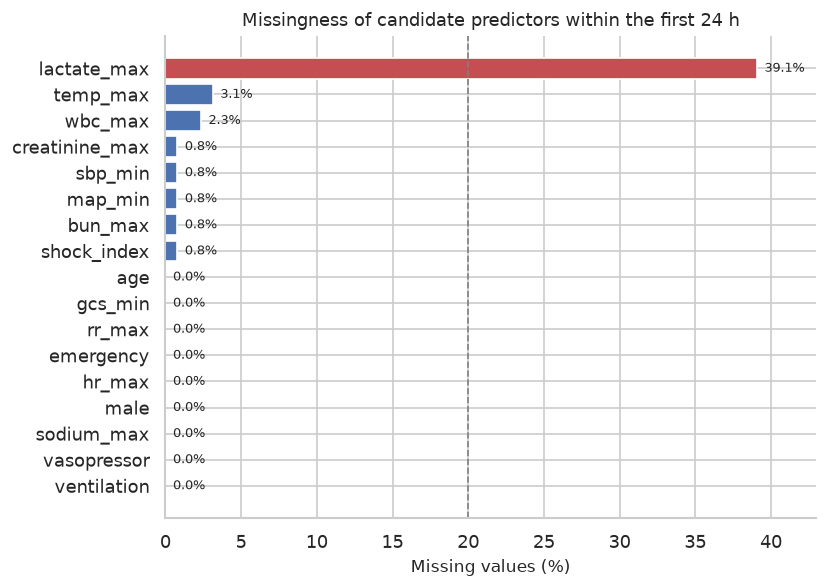

In [10]:
MODEL_FEATURES = [
    "age", "male", "emergency",
    "hr_max", "sbp_min", "map_min", "rr_max", "temp_max", "gcs_min",
    "creatinine_max", "bun_max", "lactate_max", "wbc_max", "sodium_max",
    "shock_index", "vasopressor", "ventilation",
]

missing = (
    analytic[MODEL_FEATURES]
    .isna().mean().sort_values(ascending=False)
    .rename("Missing proportion").to_frame()
)
missing["Missing n"] = analytic[MODEL_FEATURES].isna().sum()
missing["Available n"] = len(analytic) - missing["Missing n"]
missing.index.name = "Variable"
display(missing)
missing.to_csv(TAB_DIR / "table_missingness.csv")

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#C44E52" if v > 0.2 else "#4C72B0" for v in missing["Missing proportion"]]
ax.barh(missing.index[::-1], missing["Missing proportion"][::-1] * 100, color=colors[::-1])
ax.axvline(20, color="grey", ls="--", lw=1)
ax.set_xlabel("Missing values (%)")
ax.set_title("Missingness of candidate predictors within the first 24 h")
ax.set_xlim(0, max(25, missing["Missing proportion"].max() * 110))
for i, v in enumerate(missing["Missing proportion"][::-1] * 100):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
savefig(fig, "fig02_missingness")
plt.show()

### 2.4 队列流程图 / Cohort flow

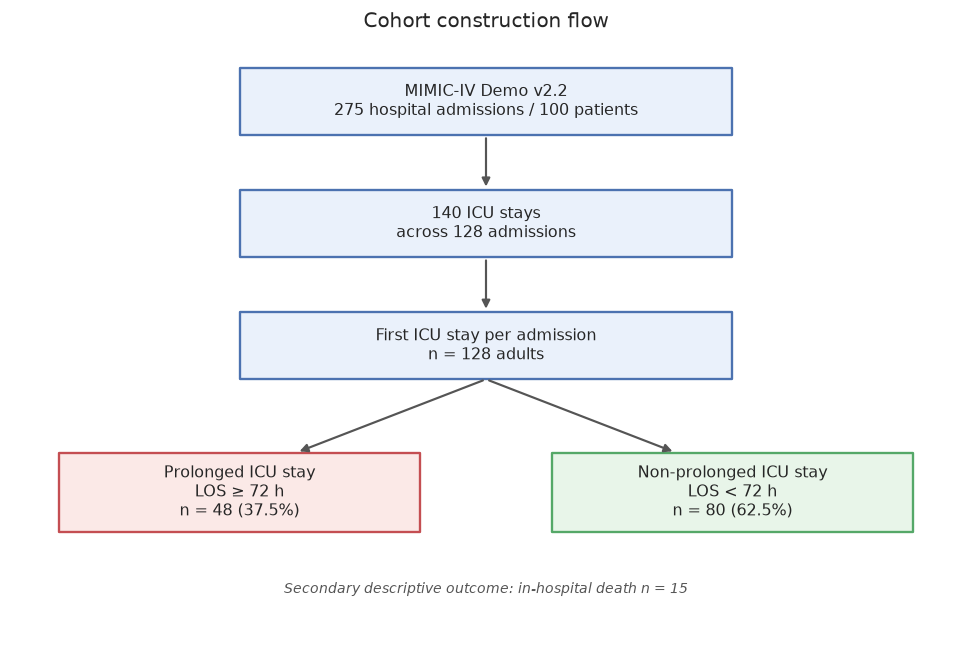

In [11]:
fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")


def add_box(x, y, w, h, text, fc="#EAF1FB", ec="#4C72B0"):
    box = plt.Rectangle((x, y), w, h, facecolor=fc, edgecolor=ec, lw=1.4,
                        joinstyle="round", zorder=2)
    ax.add_patch(box)
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
            fontsize=9.5, zorder=3, wrap=True)


def add_arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.3))


add_box(2.4, 8.4, 5.2, 1.1, "MIMIC-IV Demo v2.2\n275 hospital admissions / 100 patients")
add_box(2.4, 6.4, 5.2, 1.1, f"{n_icu_stays} ICU stays\nacross {n_admissions_with_icu} admissions")
add_box(2.4, 4.4, 5.2, 1.1, f"First ICU stay per admission\nn = {n_final} adults")
add_box(0.5, 1.9, 3.8, 1.3, f"Prolonged ICU stay\nLOS ≥ 72 h\nn = {n_events} ({n_events/n_final:.1%})", fc="#FBE9E7", ec="#C44E52")
add_box(5.7, 1.9, 3.8, 1.3, f"Non-prolonged ICU stay\nLOS < 72 h\nn = {n_final - n_events} ({(n_final-n_events)/n_final:.1%})", fc="#E8F5E9", ec="#55A868")
add_arrow(5.0, 8.4, 5.0, 7.5)
add_arrow(5.0, 6.4, 5.0, 5.5)
add_arrow(5.0, 4.4, 3.0, 3.2)
add_arrow(5.0, 4.4, 7.0, 3.2)
ax.text(5.0, 0.9, f"Secondary descriptive outcome: in-hospital death n = {n_deaths}",
        ha="center", fontsize=8.5, style="italic", color="#555555")
ax.set_title("Cohort construction flow", fontsize=12)
plt.tight_layout()
savefig(fig, "fig01_cohort_flow")
plt.show()

## 3. 统计分析 / Statistical analysis

### 3.1 基线特征表（Table 1）

连续变量以中位数 [IQR] 描述，组间比较采用 Mann–Whitney U 检验；分类变量以 n (%) 描述，采用卡方检验（期望频数 < 5 时用 Fisher 精确检验）；同时报告标准化均值差（SMD）。

In [12]:
CONTINUOUS_VARS = {
    "age": "Age (years)",
    "hr_max": "Heart rate, max (bpm)",
    "sbp_min": "Systolic BP, min (mmHg)",
    "map_min": "Mean arterial pressure, min (mmHg)",
    "rr_max": "Respiratory rate, max (/min)",
    "temp_max": "Temperature, max (°C)",
    "gcs_min": "GCS, min",
    "creatinine_max": "Creatinine, max (mg/dL)",
    "bun_max": "BUN, max (mg/dL)",
    "lactate_max": "Lactate, max (mmol/L)",
    "wbc_max": "WBC, max (×10⁹/L)",
    "sodium_max": "Sodium, max (mmol/L)",
    "shock_index": "Shock index (HR/SBP)",
}
BINARY_VARS = {
    "male": "Male sex",
    "emergency": "Emergency admission",
    "vasopressor": "Vasopressor use ≤24 h",
    "ventilation": "Mechanical ventilation ≤24 h",
    "hospital_expire_flag": "In-hospital death",
}
CATEGORICAL_VARS = {
    "first_careunit": "First ICU type",
}


def smd_continuous(x1, x0):
    m1, m0 = np.nanmean(x1), np.nanmean(x0)
    s1, s0 = np.nanstd(x1, ddof=1), np.nanstd(x0, ddof=1)
    denom = np.sqrt((s1 ** 2 + s0 ** 2) / 2)
    return (m1 - m0) / denom if denom > 0 else np.nan


def smd_binary(p1, p0):
    denom = np.sqrt((p1 * (1 - p1) + p0 * (1 - p0)) / 2)
    return (p1 - p0) / denom if denom > 0 else np.nan


def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def fmt_median_iqr(x):
    x = pd.Series(x).dropna()
    if len(x) == 0:
        return "NA"
    q1, q2, q3 = np.percentile(x, [25, 50, 75])
    return f"{q2:.1f} [{q1:.1f}, {q3:.1f}]"


rows = []
for var, label in CONTINUOUS_VARS.items():
    x1 = analytic.loc[analytic["outcome"] == 1, var].dropna()
    x0 = analytic.loc[analytic["outcome"] == 0, var].dropna()
    p = stats.mannwhitneyu(x1, x0, alternative="two-sided").pvalue if len(x1) and len(x0) else np.nan
    rows.append({
        "Variable": label,
        "Overall (n = {})".format(len(analytic)): fmt_median_iqr(analytic[var]),
        "No (n = {})".format(int((analytic["outcome"] == 0).sum())): fmt_median_iqr(analytic.loc[analytic["outcome"] == 0, var]),
        "Yes (n = {})".format(int((analytic["outcome"] == 1).sum())): fmt_median_iqr(analytic.loc[analytic["outcome"] == 1, var]),
        "p": fmt_p(p),
        "SMD": f"{smd_continuous(x1, x0):.2f}",
    })

for var, label in BINARY_VARS.items():
    tab = pd.crosstab(analytic[var], analytic["outcome"])
    if tab.shape == (2, 2):
        p = stats.fisher_exact(tab.values)[1] if (tab.values < 5).any() else stats.chi2_contingency(tab.values)[1]
    else:
        p = stats.chi2_contingency(tab.values)[1]
    p1 = analytic.loc[analytic["outcome"] == 1, var].mean()
    p0 = analytic.loc[analytic["outcome"] == 0, var].mean()
    rows.append({
        "Variable": label,
        "Overall (n = {})".format(len(analytic)): f"{int(analytic[var].sum())} ({analytic[var].mean():.1%})",
        "No (n = {})".format(int((analytic["outcome"] == 0).sum())): f"{int(analytic.loc[analytic['outcome'] == 0, var].sum())} ({p0:.1%})",
        "Yes (n = {})".format(int((analytic["outcome"] == 1).sum())): f"{int(analytic.loc[analytic['outcome'] == 1, var].sum())} ({p1:.1%})",
        "p": fmt_p(p),
        "SMD": f"{smd_binary(p1, p0):.2f}",
    })

for var, label in CATEGORICAL_VARS.items():
    levels = sorted(analytic[var].dropna().unique())
    tab = pd.crosstab(analytic[var], analytic["outcome"])
    p = stats.chi2_contingency(tab.values)[1] if tab.shape[0] > 1 else np.nan
    for i, level in enumerate(levels):
        ind = (analytic[var] == level).astype(int)
        p1 = ind[analytic["outcome"] == 1].mean()
        p0 = ind[analytic["outcome"] == 0].mean()
        rows.append({
            "Variable": f"{label}: {level}" if i == 0 else f"    {level}",
            "Overall (n = {})".format(len(analytic)): f"{int(ind.sum())} ({ind.mean():.1%})",
            "No (n = {})".format(int((analytic["outcome"] == 0).sum())): f"{int(ind[analytic['outcome'] == 0].sum())} ({p0:.1%})",
            "Yes (n = {})".format(int((analytic["outcome"] == 1).sum())): f"{int(ind[analytic['outcome'] == 1].sum())} ({p1:.1%})",
            "p": fmt_p(p) if i == 0 else "",
            "SMD": f"{smd_binary(p1, p0):.2f}",
        })

table1 = pd.DataFrame(rows)
display(table1)
table1.to_csv(TAB_DIR / "table1_baseline.csv", index=False)

,Variable,Overall (n = 128),No (n = 80),Yes (n = 48),p,SMD
0,Age (years),"63.0 [52.0, 72.8]","63.5 [52.8, 71.2]","63.0 [51.0, 78.0]",0.811,0.04
1,"Heart rate, max (bpm)","105.5 [94.0, 118.2]","103.0 [91.0, 113.2]","113.5 [97.5, 127.5]",0.002,0.60
2,"Systolic BP, min (mmHg)","90.0 [80.0, 101.0]","92.0 [84.5, 102.0]","86.5 [74.5, 92.2]",0.002,-0.63
3,"Mean arterial pressure, min (mmHg)","60.0 [52.5, 66.0]","62.0 [55.0, 66.0]","57.5 [47.0, 62.2]",0.002,-0.67
4,"Respiratory rate, max (/min)","27.0 [24.0, 30.2]","26.0 [22.0, 31.0]","28.5 [25.0, 30.0]",0.166,0.14
5,"Temperature, max (°C)","37.2 [36.9, 37.6]","37.1 [36.9, 37.4]","37.3 [37.1, 38.1]",0.010,0.54
6,"GCS, min","14.0 [5.0, 15.0]","14.0 [10.8, 15.0]","8.0 [3.0, 14.0]",<0.001,-0.69
7,"Creatinine, max (mg/dL)","0.9 [0.7, 1.6]","0.9 [0.6, 1.3]","1.1 [0.7, 2.2]",0.095,0.16
8,"BUN, max (mg/dL)","19.0 [14.0, 34.5]","18.0 [13.0, 28.0]","22.0 [15.0, 45.0]",0.042,0.37
9,"Lactate, max (mmol/L)","2.2 [1.4, 3.1]","1.8 [1.3, 2.7]","2.8 [1.6, 4.4]",0.009,0.53


### 3.2 单因素 logistic 回归 / Univariate odds ratios

连续变量按 1 个标准差（SD）标准化，OR 表示每增加 1 SD 的比值比；分类变量为相对参照组的比值比。

,Variable,Unit,OR,CI_low,CI_high,p_fmt
0,"MAP, min",per 1 SD,0.479,0.311,0.740,<0.001
1,"Systolic BP, min",per 1 SD,0.496,0.321,0.765,0.002
2,"GCS, min",per 1 SD,0.510,0.351,0.742,<0.001
3,Male sex,yes vs no,0.778,0.379,1.594,0.493
4,Emergency admission,yes vs no,0.834,0.381,1.826,0.651
5,Age,per 1 SD,1.039,0.725,1.489,0.834
6,"Respiratory rate, max",per 1 SD,1.145,0.801,1.636,0.459
7,"Creatinine, max",per 1 SD,1.172,0.820,1.675,0.383
8,"Sodium, max",per 1 SD,1.301,0.897,1.886,0.165
9,"BUN, max",per 1 SD,1.479,1.007,2.173,0.046


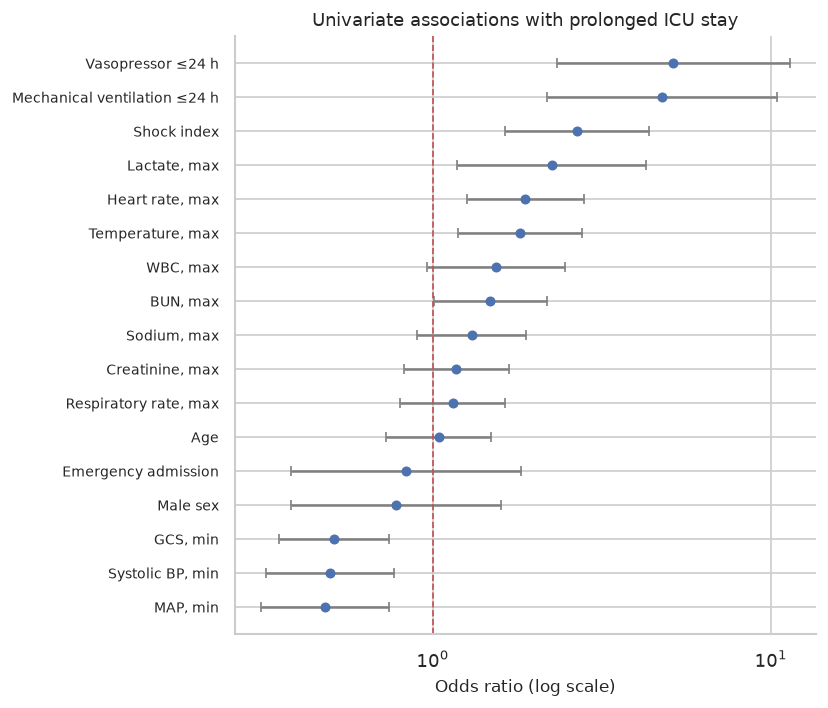

In [13]:
or_rows = []
FEATURE_LABELS = {
    "age": "Age", "male": "Male sex", "emergency": "Emergency admission",
    "hr_max": "Heart rate, max", "sbp_min": "Systolic BP, min",
    "map_min": "MAP, min", "rr_max": "Respiratory rate, max",
    "temp_max": "Temperature, max", "gcs_min": "GCS, min",
    "creatinine_max": "Creatinine, max", "bun_max": "BUN, max",
    "lactate_max": "Lactate, max", "wbc_max": "WBC, max",
    "sodium_max": "Sodium, max", "shock_index": "Shock index",
    "vasopressor": "Vasopressor ≤24 h", "ventilation": "Mechanical ventilation ≤24 h",
}
for var in MODEL_FEATURES:
    x = analytic[var].copy()
    if var not in ["male", "emergency", "vasopressor", "ventilation"]:
        sd = x.std()
        x = (x - x.mean()) / sd if sd > 0 else x * 0
        unit = "per 1 SD"
    else:
        unit = "yes vs no"
    x = x.fillna(x.median())
    X = sm.add_constant(x)
    try:
        fit = sm.Logit(analytic["outcome"], X).fit(disp=0)
        beta = fit.params.iloc[1]
        se = fit.bse.iloc[1]
        p = fit.pvalues.iloc[1]
        or_rows.append({
            "Variable": FEATURE_LABELS[var],
            "Unit": unit,
            "OR": np.exp(beta),
            "CI_low": np.exp(beta - 1.96 * se),
            "CI_high": np.exp(beta + 1.96 * se),
            "p": p,
        })
    except Exception as exc:
        print(f"Skip {var}: {exc}")

or_table = pd.DataFrame(or_rows).sort_values("OR", ascending=True).reset_index(drop=True)
or_table["p_fmt"] = or_table["p"].apply(fmt_p)
display(or_table[["Variable", "Unit", "OR", "CI_low", "CI_high", "p_fmt"]])
or_table.to_csv(TAB_DIR / "table2_univariate_or.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6))
ypos = np.arange(len(or_table))
ax.errorbar(
    or_table["OR"], ypos,
    xerr=[or_table["OR"] - or_table["CI_low"], or_table["CI_high"] - or_table["OR"]],
    fmt="o", color="#4C72B0", ecolor="#7F7F7F", capsize=3, ms=5,
)
ax.axvline(1, color="#C44E52", ls="--", lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels(or_table["Variable"], fontsize=8.5)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio (log scale)")
ax.set_title("Univariate associations with prolonged ICU stay")
plt.tight_layout()
savefig(fig, "fig05_univariate_or")
plt.show()

### 3.3 变量分布与相关性 / Distributions and correlations

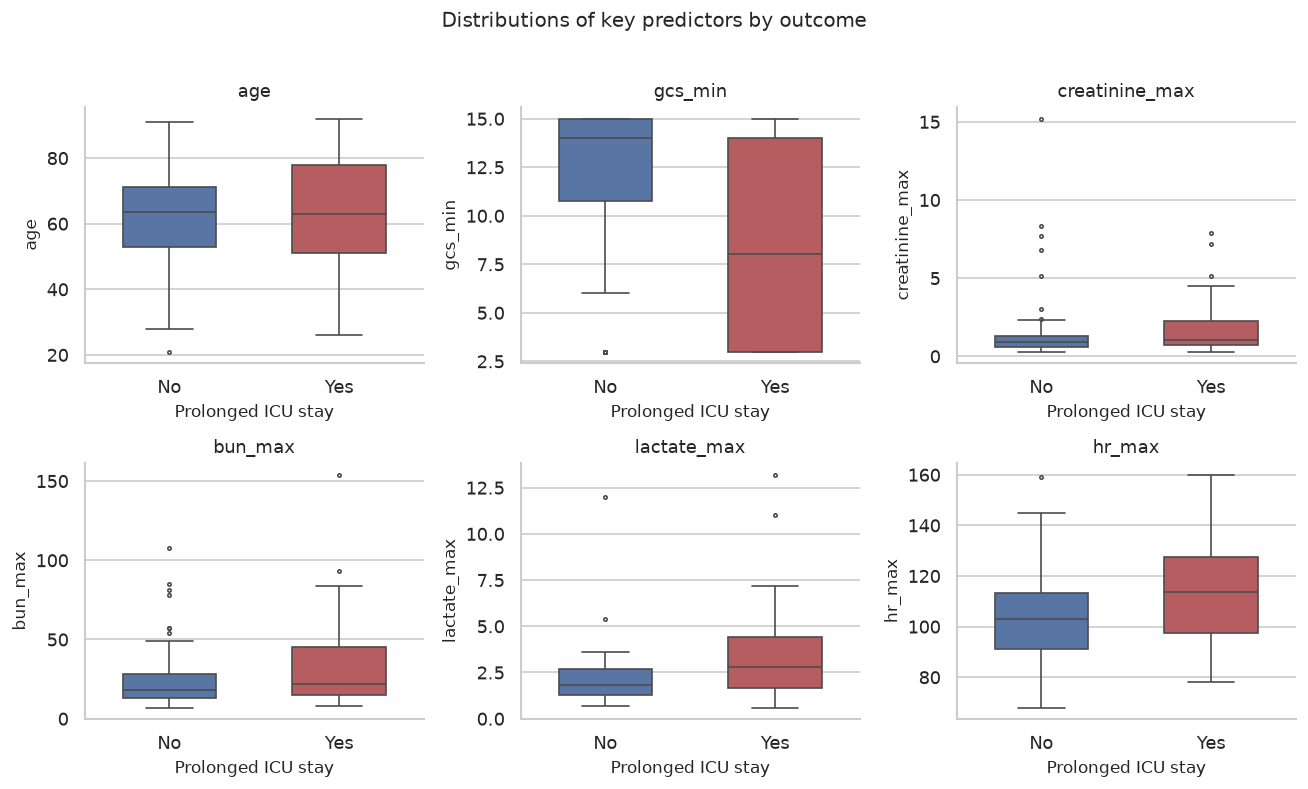

In [14]:
plot_vars = ["age", "gcs_min", "creatinine_max", "bun_max", "lactate_max", "hr_max"]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
for ax, var in zip(axes.flat, plot_vars):
    plot_df = analytic[[var, "outcome"]].copy()
    plot_df["Group"] = plot_df["outcome"].map({0: "No", 1: "Yes"})
    sns.boxplot(
        data=plot_df, x="Group", y=var, hue="Group", ax=ax,
        palette=PALETTE, width=0.55, legend=False, fliersize=2,
    )
    ax.set_xlabel("Prolonged ICU stay")
    ax.set_ylabel(var)
    ax.set_title(var)
plt.suptitle("Distributions of key predictors by outcome", y=1.02, fontsize=12)
plt.tight_layout()
savefig(fig, "fig03_distributions")
plt.show()

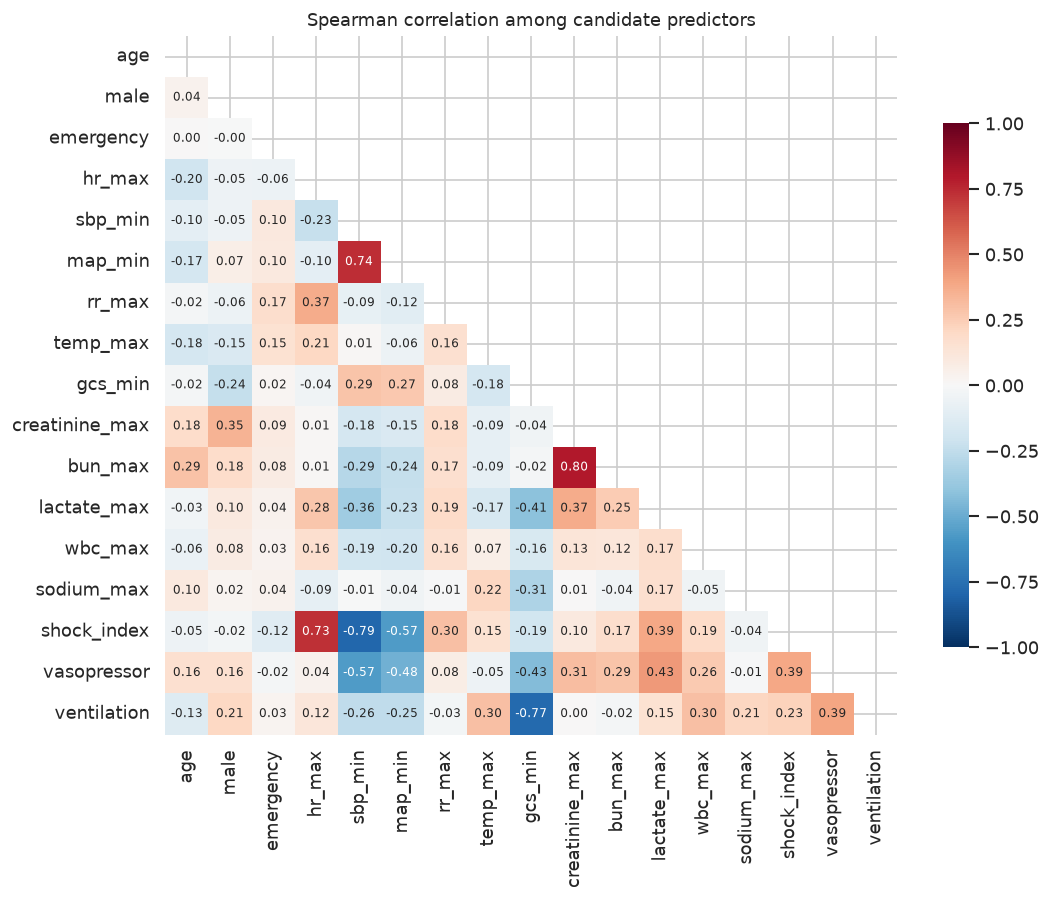

In [15]:
corr = analytic[MODEL_FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.2, 7.6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 7},
    cbar_kws={"shrink": 0.75}, ax=ax,
)
ax.set_title("Spearman correlation among candidate predictors")
plt.tight_layout()
savefig(fig, "fig04_correlation")
plt.show()

## 4. 预测模型建立 / Predictive modeling

### 4.1 数据划分

按 70/30 分层划分训练集与测试集；所有插补与标准化均在训练集内拟合，避免数据泄漏。

In [16]:
X = analytic[MODEL_FEATURES].copy()
y = analytic["outcome"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
print("Training set:", X_train.shape, "events:", int(y_train.sum()))
print("Test set    :", X_test.shape, "events:", int(y_test.sum()))
print("Event rate  : train {:.1%}, test {:.1%}".format(y_train.mean(), y_test.mean()))

split_info = analytic.loc[X_train.index, ["stay_id", "hadm_id"]].copy()
split_info["split"] = "train"
split_info = pd.concat([
    split_info,
    analytic.loc[X_test.index, ["stay_id", "hadm_id"]].assign(split="test"),
])
split_info.to_csv(OUT_DIR / "train_test_split.csv", index=False)

Training set: (89, 17) events: 33
Test set    : (39, 17) events: 15
Event rate  : train 37.1%, test 38.5%


### 4.2 候选模型与超参数搜索

比较三种模型：正则化 logistic 回归、随机森林、XGBoost。使用 5 折分层交叉验证，以 AUROC 为优化目标。

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_specs = {
    "Logistic": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                solver="lbfgs", max_iter=5000,
                random_state=RANDOM_STATE,
            )),
        ]),
        "grid": {"model__C": [0.01, 0.1, 1.0, 10.0]},
    },
    "Random Forest": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=500,
                random_state=RANDOM_STATE, n_jobs=-1,
            )),
        ]),
        "grid": {
            "model__max_depth": [2, 3, 4, None],
            "model__min_samples_leaf": [2, 4, 8],
            "model__max_features": ["sqrt", 0.5],
        },
    },
    "XGBoost": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", xgb.XGBClassifier(
                n_estimators=400, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8,
                random_state=RANDOM_STATE, eval_metric="logloss",
                n_jobs=-1,
            )),
        ]),
        "grid": {
            "model__max_depth": [2, 3],
            "model__reg_lambda": [1, 5, 10],
        },
    },
}

fitted = {}
cv_summary = []
for name, spec in model_specs.items():
    gs = GridSearchCV(
        spec["pipeline"], spec["grid"],
        scoring="roc_auc", cv=cv, n_jobs=-1, refit=True,
    )
    gs.fit(X_train, y_train)
    fitted[name] = gs
    best_idx = gs.best_index_
    cv_summary.append({
        "Model": name,
        "CV AUC mean": gs.cv_results_["mean_test_score"][best_idx],
        "CV AUC SD": gs.cv_results_["std_test_score"][best_idx],
        "Best parameters": json.dumps(gs.best_params_),
    })
    print(f"[{name}] best CV AUC = {gs.best_score_:.3f} | {gs.best_params_}")

cv_summary = pd.DataFrame(cv_summary).sort_values("CV AUC mean", ascending=False)
display(cv_summary)
cv_summary.to_csv(TAB_DIR / "table3_model_cv.csv", index=False)

[Logistic] best CV AUC = 0.760 | {'model__C': 0.1}


[Random Forest] best CV AUC = 0.778 | {'model__max_depth': 3, 'model__max_features': 0.5, 'model__min_samples_leaf': 8}


[XGBoost] best CV AUC = 0.725 | {'model__max_depth': 3, 'model__reg_lambda': 10}


,Model,CV AUC mean,CV AUC SD,Best parameters
1,Random Forest,0.778,0.129,"{""model__max_depth"": 3, ""model__max_features"":..."
0,Logistic,0.760,0.139,"{""model__C"": 0.1}"
2,XGBoost,0.725,0.133,"{""model__max_depth"": 3, ""model__reg_lambda"": 10}"


## 5. 模型评估与可视化 / Evaluation & visualization

### 5.1 测试集性能与 Bootstrap 置信区间

In [18]:
def bootstrap_auc(y_true, y_prob, n_boot=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[idx], y_prob[idx]))
    return np.percentile(aucs, [2.5, 97.5])


def threshold_metrics(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "PPV": tp / (tp + fp) if (tp + fp) else np.nan,
        "NPV": tn / (tn + fn) if (tn + fn) else np.nan,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
    }


predictions = {}
performance_rows = []
for name, gs in fitted.items():
    prob = gs.predict_proba(X_test)[:, 1]
    predictions[name] = prob
    fpr, tpr, thr = roc_curve(y_test, prob)
    youden_idx = np.argmax(tpr - fpr)
    best_thr = thr[youden_idx]
    tm = threshold_metrics(y_test, prob, best_thr)
    ci_low, ci_high = bootstrap_auc(y_test, prob)
    performance_rows.append({
        "Model": name,
        "CV AUC": f"{gs.best_score_:.3f}",
        "Test AUROC": roc_auc_score(y_test, prob),
        "AUROC 95% CI": f"{ci_low:.3f}–{ci_high:.3f}",
        "PR-AUC": average_precision_score(y_test, prob),
        "Brier": brier_score_loss(y_test, prob),
        "Sensitivity": tm["Sensitivity"],
        "Specificity": tm["Specificity"],
        "PPV": tm["PPV"],
        "NPV": tm["NPV"],
        "F1": tm["F1"],
        "Threshold": best_thr,
    })

performance = pd.DataFrame(performance_rows).sort_values("Test AUROC", ascending=False).reset_index(drop=True)
performance_export = performance.copy()
for col in ["Test AUROC", "PR-AUC", "Brier", "Sensitivity", "Specificity", "PPV", "NPV", "F1", "Threshold"]:
    performance_export[col] = performance_export[col].round(3)
display(performance_export)
performance_export.to_csv(TAB_DIR / "table4_model_performance.csv", index=False)

best_name = cv_summary.iloc[0]["Model"]
best_model = fitted[best_name].best_estimator_
best_prob = predictions[best_name]
print(f"Best model selected by cross-validation: {best_name}")

,Model,CV AUC,Test AUROC,AUROC 95% CI,PR-AUC,Brier,Sensitivity,Specificity,PPV,NPV,F1,Threshold
0,Logistic,0.760,0.750,0.566–0.906,0.702,0.183,0.667,0.833,0.714,0.800,0.690,0.409
1,Random Forest,0.778,0.739,0.559–0.883,0.698,0.204,0.733,0.708,0.611,0.810,0.667,0.315
2,XGBoost,0.725,0.703,0.515–0.864,0.689,0.212,0.533,0.833,0.667,0.741,0.593,0.497


Best model selected by cross-validation: Random Forest


### 5.2 ROC 与 PR 曲线

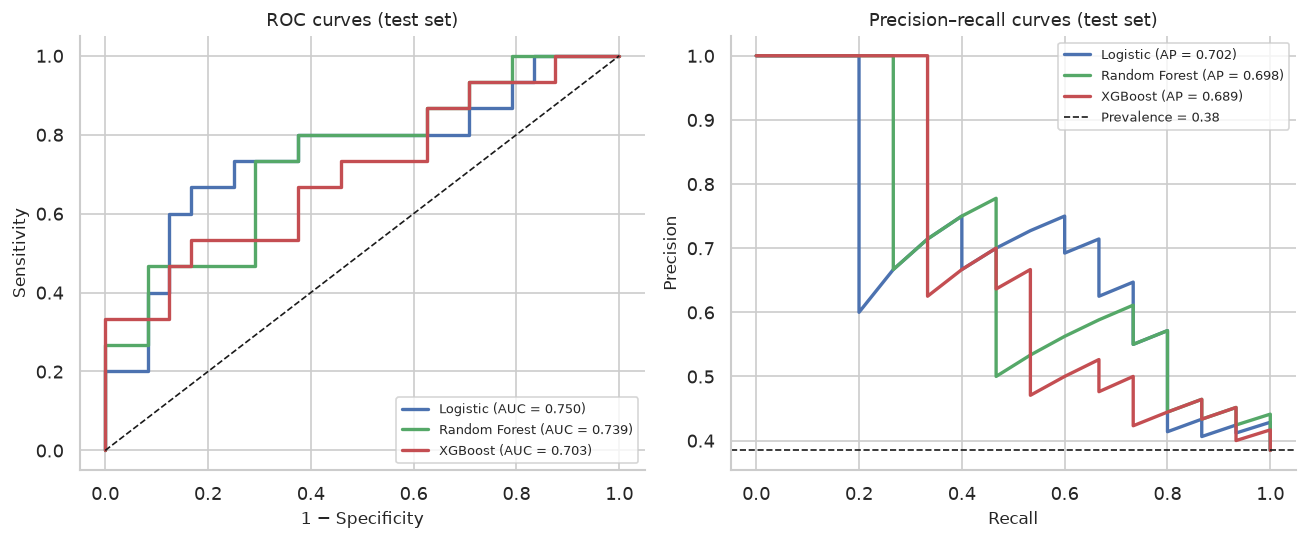

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

for name, prob in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, lw=2, color=COLORS[name],
                 label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("1 − Specificity")
axes[0].set_ylabel("Sensitivity")
axes[0].set_title("ROC curves (test set)")
axes[0].legend(loc="lower right", fontsize=8)

for name, prob in predictions.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(recall, precision, lw=2, color=COLORS[name],
                 label=f"{name} (AP = {average_precision_score(y_test, prob):.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1,
                label=f"Prevalence = {y_test.mean():.2f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curves (test set)")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
savefig(fig, "fig06_roc_pr")
plt.show()

### 5.3 校准曲线 / Calibration

校准曲线评估预测概率与真实风险的一致性；Brier score 同时考虑区分度与校准。

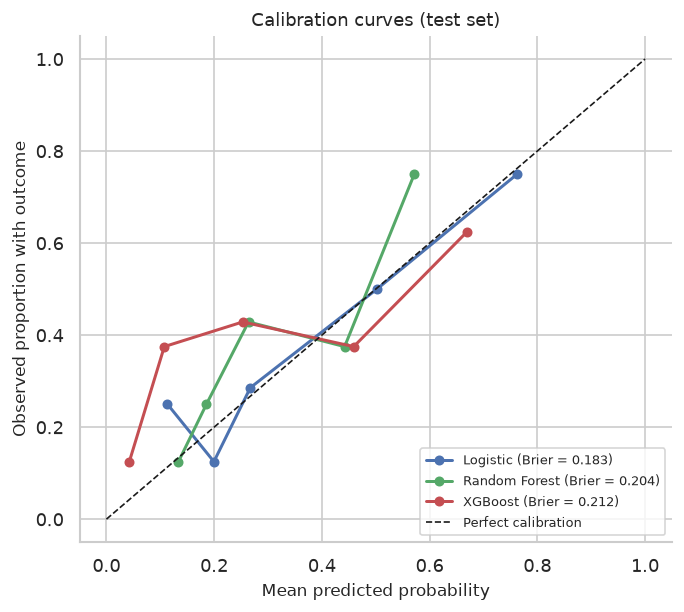

In [20]:
fig, ax = plt.subplots(figsize=(5.8, 5.2))
for name, prob in predictions.items():
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", lw=1.8, ms=5,
            color=COLORS[name],
            label=f"{name} (Brier = {brier_score_loss(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed proportion with outcome")
ax.set_title("Calibration curves (test set)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
savefig(fig, "fig07_calibration")
plt.show()

### 5.4 决策曲线分析 / Decision curve analysis

决策曲线展示不同阈值概率下模型的临床净获益（net benefit），并与“全部干预”和“不干预”比较。

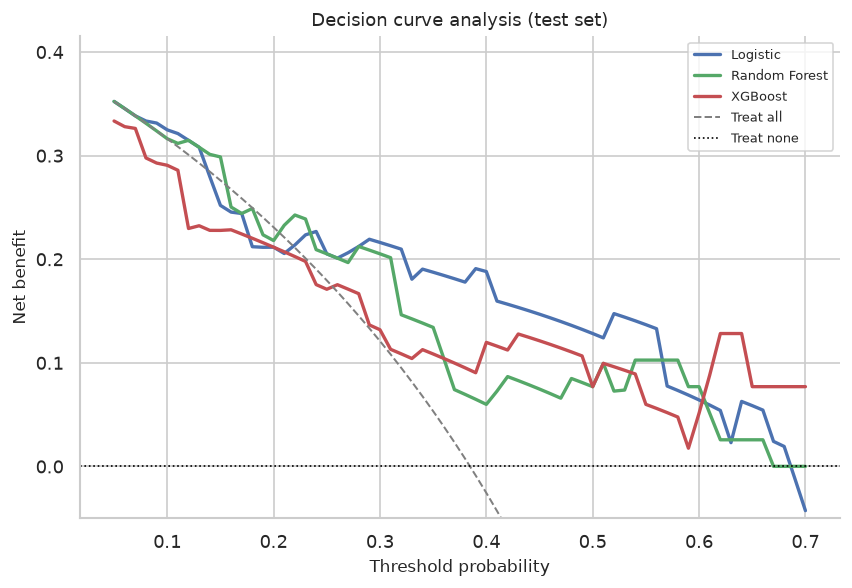

In [21]:
def net_benefit(y_true, y_prob, thresholds):
    y_true = np.asarray(y_true)
    n = len(y_true)
    out = []
    for pt in thresholds:
        pred = y_prob >= pt
        tp = np.sum(pred & (y_true == 1))
        fp = np.sum(pred & (y_true == 0))
        out.append(tp / n - (fp / n) * (pt / (1 - pt)))
    return np.array(out)


thresholds = np.linspace(0.05, 0.70, 66)
prevalence = y_test.mean()

fig, ax = plt.subplots(figsize=(7.2, 5.0))
for name, prob in predictions.items():
    nb = net_benefit(y_test, prob, thresholds)
    ax.plot(thresholds, nb, lw=2, color=COLORS[name], label=name)
ax.plot(thresholds, prevalence - (1 - prevalence) * thresholds / (1 - thresholds),
        color="grey", ls="--", lw=1.2, label="Treat all")
ax.axhline(0, color="black", ls=":", lw=1, label="Treat none")
ax.set_ylim(-0.05, max(0.05, prevalence * 1.08))
ax.set_xlabel("Threshold probability")
ax.set_ylabel("Net benefit")
ax.set_title("Decision curve analysis (test set)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
savefig(fig, "fig08_dca")
plt.show()

### 5.5 混淆矩阵与阈值表现

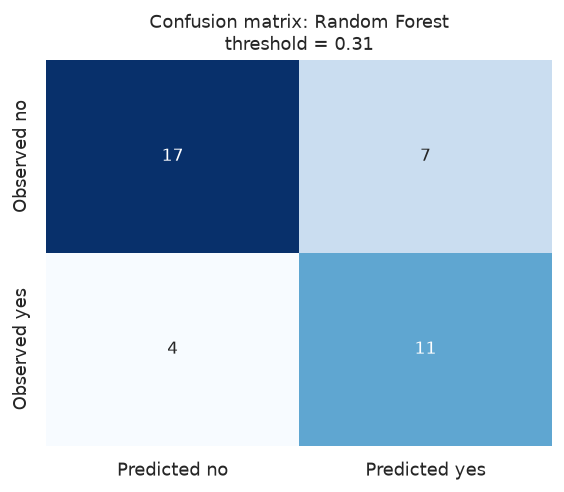

Best model: Random Forest, Youden threshold: 0.315
{'Threshold': np.float64(0.3146957015750094), 'Sensitivity': np.float64(0.7333333333333333), 'Specificity': np.float64(0.7083333333333334), 'PPV': np.float64(0.6111111111111112), 'NPV': np.float64(0.8095238095238095), 'F1': 0.6666666666666666, 'Accuracy': 0.717948717948718}


In [22]:
fpr, tpr, thr = roc_curve(y_test, best_prob)
best_thr = thr[np.argmax(tpr - fpr)]
y_pred = (best_prob >= best_thr).astype(int)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Predicted no", "Predicted yes"],
    yticklabels=["Observed no", "Observed yes"], ax=ax,
)
ax.set_title(f"Confusion matrix: {best_name}\nthreshold = {best_thr:.2f}")
plt.tight_layout()
savefig(fig, "fig09_confusion_matrix")
plt.show()

print(f"Best model: {best_name}, Youden threshold: {best_thr:.3f}")
print(threshold_metrics(y_test, best_prob, best_thr))

### 5.6 特征重要性 / Feature importance

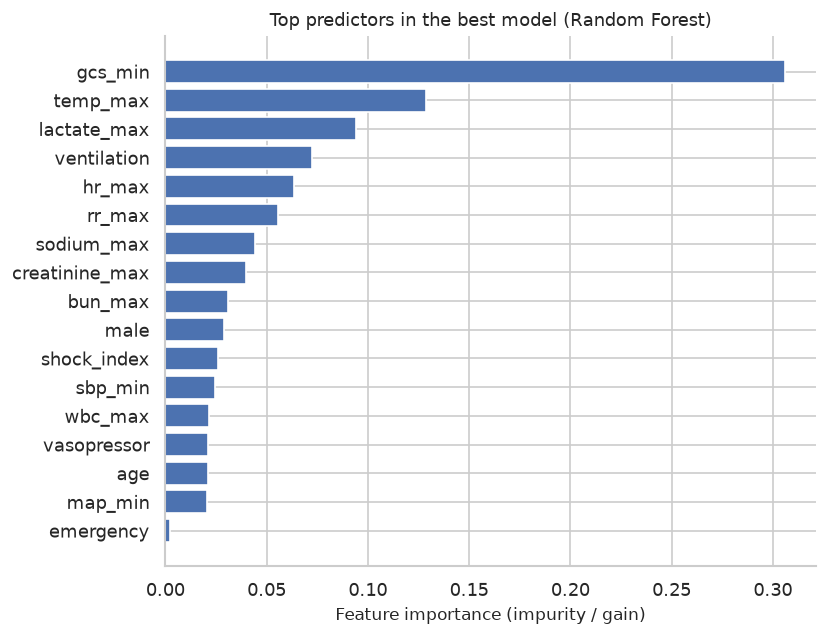

,Importance
gcs_min,0.306
temp_max,0.129
lactate_max,0.094
ventilation,0.072
hr_max,0.063
rr_max,0.055
sodium_max,0.044
creatinine_max,0.040
bun_max,0.031
male,0.029


In [23]:
model_step = best_model.named_steps["model"]
if hasattr(model_step, "feature_importances_"):
    importances = pd.Series(model_step.feature_importances_, index=MODEL_FEATURES)
    importance_label = "Feature importance (impurity / gain)"
else:
    importances = pd.Series(np.abs(model_step.coef_[0]), index=MODEL_FEATURES)
    importance_label = "Absolute standardized coefficient"

importances = importances.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(7, 5.4))
ax.barh(importances.index, importances.values, color="#4C72B0")
ax.set_xlabel(importance_label)
ax.set_title(f"Top predictors in the best model ({best_name})")
plt.tight_layout()
savefig(fig, "fig10_feature_importance")
plt.show()
display(importances.sort_values(ascending=False).to_frame("Importance"))

### 5.7 SHAP 可解释性分析

SHAP 值量化每个特征对单例预测的贡献，提供全局与个体层面的可解释性。

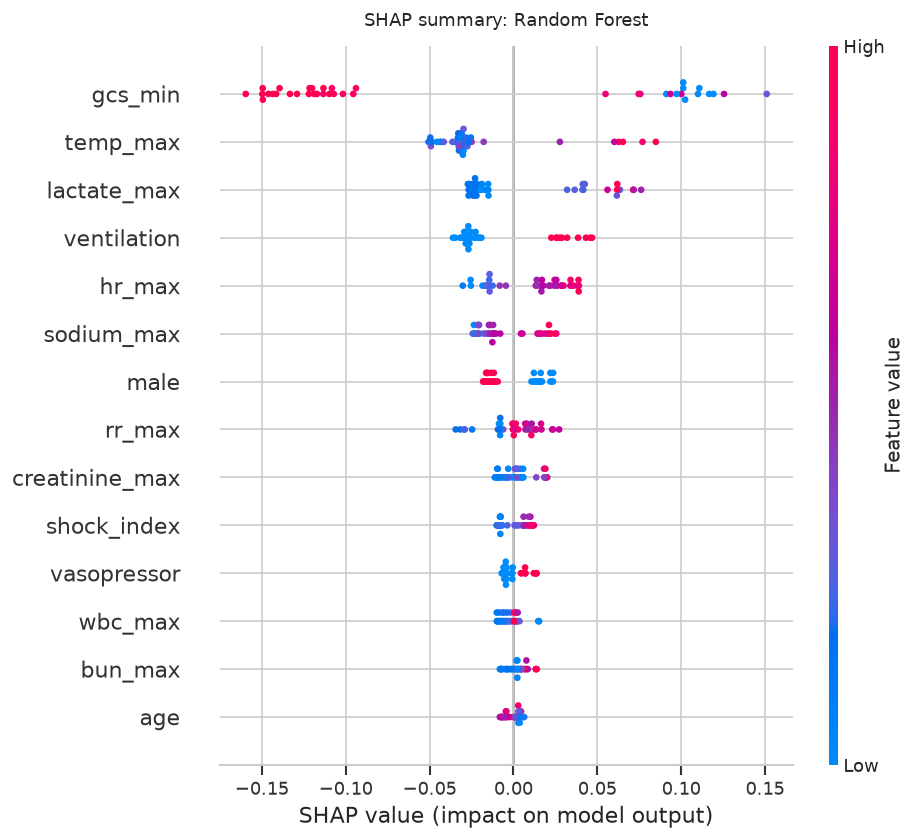

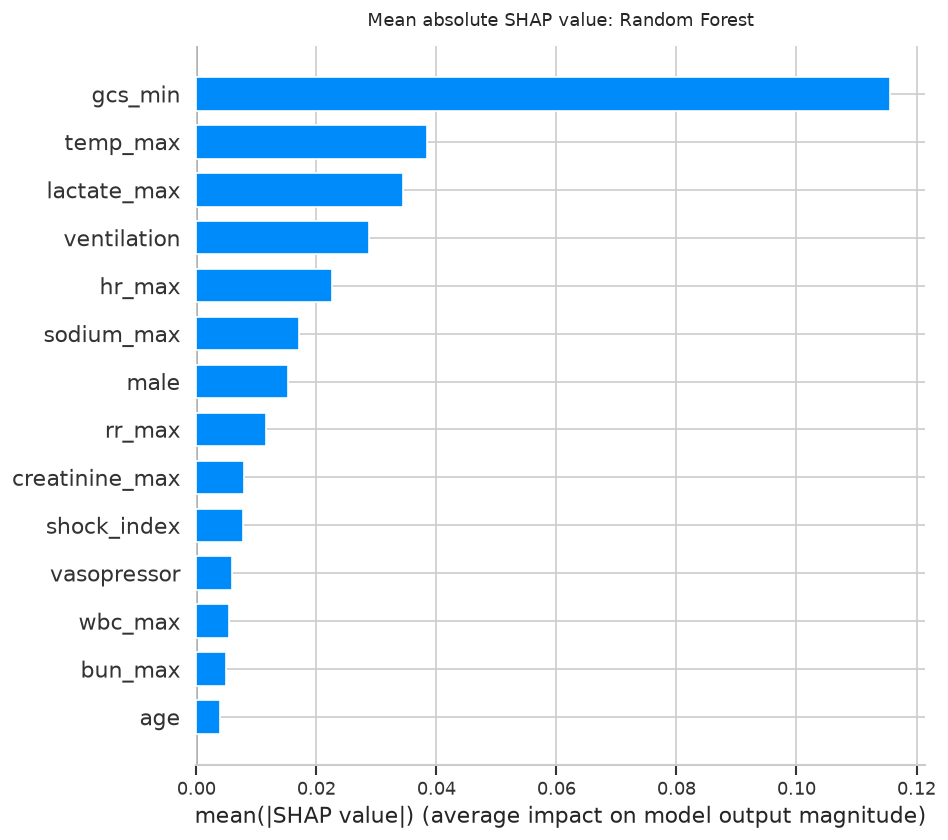

In [24]:
X_test_imputed = pd.DataFrame(
    best_model.named_steps["imputer"].transform(X_test),
    columns=MODEL_FEATURES, index=X_test.index,
)

if best_name == "Logistic":
    X_background = pd.DataFrame(
        best_model.named_steps["scaler"].transform(
            best_model.named_steps["imputer"].transform(X_train)
        ),
        columns=MODEL_FEATURES,
    )
    X_explain = pd.DataFrame(
        best_model.named_steps["scaler"].transform(X_test_imputed),
        columns=MODEL_FEATURES,
    )
    explainer = shap.LinearExplainer(best_model.named_steps["model"], X_background)
    shap_values = explainer.shap_values(X_explain)
    X_plot = X_explain
else:
    explainer = shap.TreeExplainer(model_step)
    shap_values = explainer.shap_values(X_test_imputed)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif np.ndim(shap_values) == 3:
        shap_values = shap_values[:, :, 1]
    X_plot = X_test_imputed

plt.figure()
shap.summary_plot(shap_values, X_plot, feature_names=MODEL_FEATURES, show=False, max_display=14)
plt.gca().set_title(f"SHAP summary: {best_name}", pad=12)
plt.tight_layout()
savefig(plt.gcf(), "fig11_shap_beeswarm")
plt.show()
plt.close("all")

plt.figure()
shap.summary_plot(shap_values, X_plot, feature_names=MODEL_FEATURES,
                  plot_type="bar", show=False, max_display=14)
plt.gca().set_title(f"Mean absolute SHAP value: {best_name}", pad=12)
plt.tight_layout()
savefig(plt.gcf(), "fig12_shap_bar")
plt.show()
plt.close("all")

### 5.8 交叉验证稳定性 / Cross-validation stability

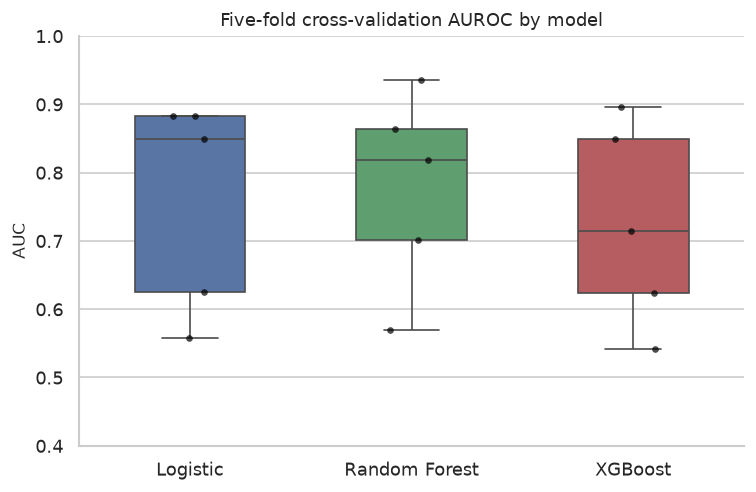

,mean,std,min,max
Model,,,,
Logistic,0.760,0.156,0.558,0.883
Random Forest,0.778,0.144,0.569,0.935
XGBoost,0.725,0.149,0.542,0.896


In [25]:
fold_rows = []
for name, gs in fitted.items():
    best_idx = gs.best_index_
    for fold in range(cv.get_n_splits()):
        fold_rows.append({
            "Model": name,
            "Fold": fold + 1,
            "AUC": gs.cv_results_[f"split{fold}_test_score"][best_idx],
        })
fold_df = pd.DataFrame(fold_rows)

fig, ax = plt.subplots(figsize=(6.4, 4.2))
sns.boxplot(data=fold_df, x="Model", y="AUC", hue="Model",
            palette=COLORS, width=0.5, legend=False, ax=ax)
sns.stripplot(data=fold_df, x="Model", y="AUC", color="black",
              size=4, alpha=0.7, ax=ax)
ax.set_ylim(0.4, 1.0)
ax.set_title("Five-fold cross-validation AUROC by model")
ax.set_xlabel("")
plt.tight_layout()
savefig(fig, "fig13_cv_stability")
plt.show()
display(fold_df.groupby("Model")["AUC"].agg(["mean", "std", "min", "max"]))

## 6. 结果导出 / Export for report and website

In [26]:
y_pred_best = (best_prob >= best_thr).astype(int)
test_predictions = analytic.loc[X_test.index, ["stay_id", "hadm_id", "age", "los", "outcome"]].copy()
for name, prob in predictions.items():
    test_predictions[f"prob_{name.replace(' ', '_').lower()}"] = prob
test_predictions["pred_best"] = y_pred_best
test_predictions.to_csv(OUT_DIR / "test_predictions.csv", index=False)

joblib.dump(best_model, OUT_DIR / "models" / "best_model.joblib")

summary = {
    "dataset": "MIMIC-IV Clinical Database Demo v2.2",
    "n_patients": int(analytic["subject_id"].nunique()),
    "n_icu_stays": int(len(analytic)),
    "n_events": int(analytic["outcome"].sum()),
    "event_rate": float(analytic["outcome"].mean()),
    "n_deaths": int(analytic["hospital_expire_flag"].sum()),
    "outcome": "Prolonged ICU stay (LOS >= 72 h)",
    "features": MODEL_FEATURES,
    "best_model": best_name,
    "best_params": fitted[best_name].best_params_,
    "cv_auc": float(fitted[best_name].best_score_),
    "test_metrics": performance.loc[performance["Model"] == best_name].iloc[0].to_dict(),
    "top_features": importances.sort_values(ascending=False).head(8).round(4).to_dict(),
}
with open(OUT_DIR / "results_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=float)

print("Saved artifacts:")
for p in sorted(OUT_DIR.glob("*")):
    print(" -", p.relative_to(ROOT))
print("\nFigures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print(" -", p.relative_to(ROOT))
print("\nTables:")
for p in sorted(TAB_DIR.glob("*.csv")):
    print(" -", p.relative_to(ROOT))

Saved artifacts:
 - notebooks/outputs/analytic_cohort.csv
 - notebooks/outputs/models
 - notebooks/outputs/results_summary.json
 - notebooks/outputs/test_predictions.csv
 - notebooks/outputs/train_test_split.csv

Figures:
 - report/figures/fig01_cohort_flow.png
 - report/figures/fig02_missingness.png
 - report/figures/fig03_distributions.png
 - report/figures/fig04_correlation.png
 - report/figures/fig05_univariate_or.png
 - report/figures/fig06_roc_pr.png
 - report/figures/fig07_calibration.png
 - report/figures/fig08_dca.png
 - report/figures/fig09_confusion_matrix.png
 - report/figures/fig10_feature_importance.png
 - report/figures/fig11_shap_beeswarm.png
 - report/figures/fig12_shap_bar.png
 - report/figures/fig13_cv_stability.png

Tables:
 - report/tables/table0_data_overview.csv
 - report/tables/table1_baseline.csv
 - report/tables/table2_univariate_or.csv
 - report/tables/table3_model_cv.csv
 - report/tables/table4_model_performance.csv
 - report/tables/table_missingness.csv


## 7. 小结 / Summary

本分析构建了一个可复现的 ICU 延长住院预测流程：

- 从 MIMIC-IV Demo 提取 128 个首次 ICU 住院，48 例（37.5%）发生延长 ICU 停留；
- 使用入 ICU 24 小时内的生命体征、实验室检查和早期干预变量；
- 比较 logistic 回归、随机森林和 XGBoost，以交叉验证 AUROC 选择模型；
- 在独立测试集上报告 AUROC、PR-AUC、Brier、校准曲线、决策曲线与 SHAP。

**局限性 / Limitations**

- Demo 队列仅 100 名患者、128 个 ICU 住院、48 个事件，统计效能有限；
- 单中心、回顾性数据，缺乏外部验证；
- 结局定义为 ICU LOS ≥ 72 小时，可能受出院流程与床位资源影响；
- 未纳入用药剂量、液体平衡、影像与时间序列动态信息。